In [ ]:
import rasterio

files = {
    "Blue (B02)": "D:\GISLab\Prog-For-GIS\Lab4\B02.tif",
    "Green (B03)": "D:\GISLab\Prog-For-GIS\Lab4\B03.tif",
    "Red (B04)": "D:\GISLab\Prog-For-GIS\Lab4\B04.tif"
}

for name, file in files.items():

    dataset = rasterio.open(file)

    print("\n", name)
    print("Width:", dataset.width)
    print("Height:", dataset.height)
    print("Bands:", dataset.count)
    print("CRS:", dataset.crs)
    print("Resolution:", dataset.res)

    dataset.close()


 Blue (B02)
Minimum: 1407
Maximum: 3803
Mean: 1687.8061702182088


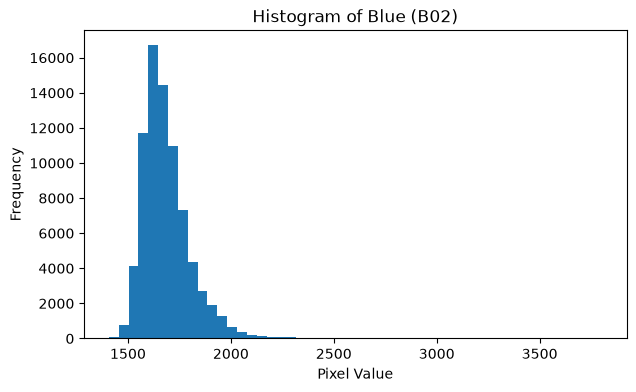


 Green (B03)
Minimum: 1493
Maximum: 3944
Mean: 1806.5523010411603


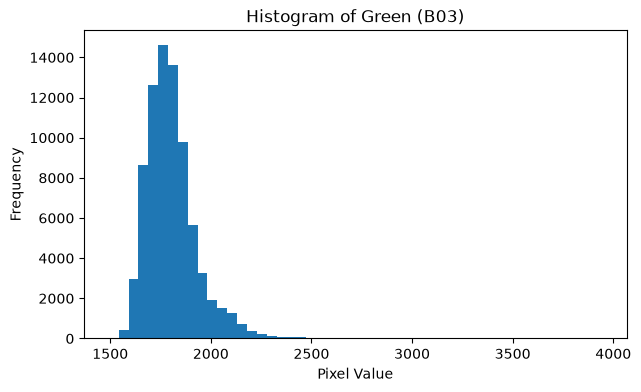


 Red (B04)
Minimum: 1327
Maximum: 3742
Mean: 1717.0200429766442


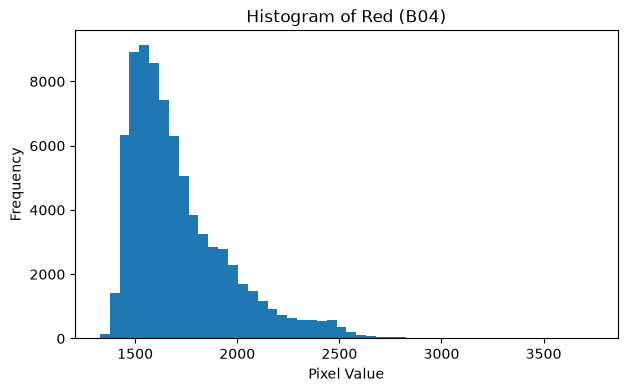

In [1]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

files = {
    "Blue (B02)": "B02.tif",
    "Green (B03)": "B03.tif",
    "Red (B04)": "B04.tif"
}

for name, file in files.items():

    with rasterio.open(file) as dataset:

        band = dataset.read(1)

        print("\n", name)
        print("Minimum:", np.min(band))
        print("Maximum:", np.max(band))
        print("Mean:", np.mean(band))

        plt.figure(figsize=(7, 4))

        plt.hist(band.flatten(), bins=50)

        plt.title("Histogram of " + name)
        plt.xlabel("Pixel Value")
        plt.ylabel("Frequency")

        plt.show()

In [2]:
import rasterio
import numpy as np

files = ["B02.tif", "B03.tif", "B04.tif"]

bands = []

for file in files:

    with rasterio.open(file) as src:

        bands.append(src.read(1))

        profile = src.profile.copy()

# Stack bands
stacked = np.stack(bands, axis=0)

profile.update(
    count=3,
    dtype=stacked.dtype
)

with rasterio.open("stacked_image.tif", "w", **profile) as dst:

    dst.write(stacked)

print("Band stacking completed!")

Band stacking completed!


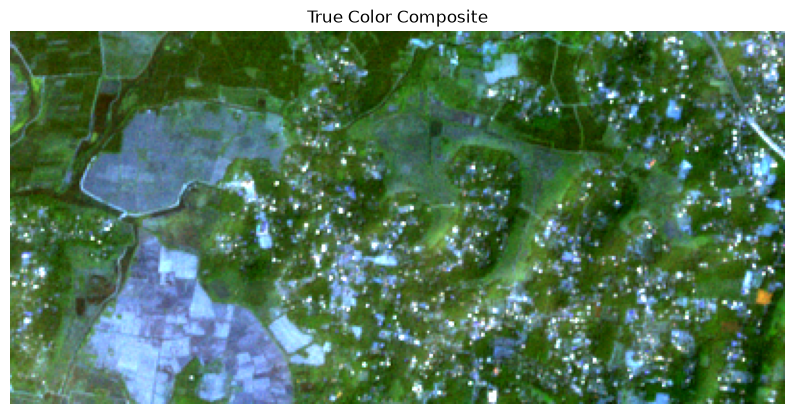

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import rasterio

with rasterio.open("stacked_image.tif") as src:

    # Read all three bands
    rgb = src.read()

# Rearrange from (bands, rows, columns)
# to (rows, columns, bands)
rgb = np.transpose(rgb, (1, 2, 0))

# Contrast enhancement using percentile stretching
p2 = np.percentile(rgb, 2)
p98 = np.percentile(rgb, 98)

rgb_display = np.clip(
    (rgb - p2) / (p98 - p2),
    0, 1
)

# Display image
plt.figure(figsize=(10, 8))
plt.imshow(rgb_display)

plt.title("True Color Composite")
plt.axis("off")
plt.show()